# Regime Structure 03 — big-move days vs normal days

Pre-registration: `discussions/Regime_Structure/007_claude_rs03_preregistration.md`. Code: `src/data_engineering/modeling/big_move_days.py`.

- **Session:** the 24 h ending at 08:00 UTC (Deribit daily expiry). Binance USD-M 1m → 5m bars, BTC/ETH/SOL/XRP, about 2 years.
- **Big-move day:** $z=\lvert\Delta\log P_{\text{session}}\rvert/\hat\sigma$ with $\hat\sigma$ = RMS of the previous 7 sessions' realised vol; BIG if $z\ge q_{85}$ (development window, per asset).
- **DURING** (what happens on those days): descriptive only. **PRE** (known at 08:00, target BIG) and **EARLY** (08:00–10:00, target BIG over the *rest* of the session 10:00→08:00): AUC big vs normal, screened on the development window, confirmed on the test window (from 2026-04-01) at a Bonferroni level over the candidates.
- **Clustering:** do big days follow big days, and do they hit all assets at once?

Environment: `RS03_ASSETS`, `RS03_N_BOOT` (default 2000), `RS03_SYNTHETIC=1`.

In [1]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import big_move_days as bm
bm = importlib.reload(bm)
from dataclasses import replace

SYNTHETIC = os.getenv('RS03_SYNTHETIC', '').strip() == '1'
ASSETS = [a.strip().upper() for a in os.getenv('RS03_ASSETS', ','.join(bm.ASSETS)).split(',') if a.strip()]
P = replace(bm.Params(), n_boot=int(os.getenv('RS03_N_BOOT', str(bm.Params().n_boot))))
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='rs03_')); BIN_DIR = None
else:
    BIN_DIR = Path(os.getenv('BINANCE_UM_DIR') or Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance').expanduser().resolve()
    OUT = PROJECT_ROOT / 'notebooks' / 'Regime_Structure' / '03'
OUT.mkdir(parents=True, exist_ok=True)
print('RS 03 |', bm.VERSION, '| synthetic' if SYNTHETIC else f'| data {BIN_DIR}', '| out', OUT)

RS 03 | big_move_days v1.0 | data D:\MarketData\Binance | out D:\Projects\deribit_market_data\notebooks\Regime_Structure\03


## 1. Sessions and big-move labels

In [2]:
RES = {}
for i, a in enumerate(ASSETS):
    if SYNTHETIC:
        df = bm.synthetic_klines(n_days=760, seed=50 + i, start='2024-10-01')
    else:
        path = BIN_DIR / f'{a}USDT_um_1m.parquet'
        if not path.exists():
            print(f'{a}: no Binance file -> skipped'); continue
        df = pd.read_parquet(path, columns=['open_time', 'close', 'volume', 'taker_buy_volume', 'trades'])
    RES[a] = bm.run_asset(df, a, P)
    del df
T = pd.concat([r['table'] for r in RES.values()], ignore_index=True)
cov = T.dropna(subset=['big']).groupby(['asset', 'window']).agg(sessions=('big', 'size'), big_days=('big', 'sum'),
                                                               big_share=('big', 'mean'), z_median=('z', 'median'))
cov['z_threshold'] = [RES[a]['threshold'] for a, _ in cov.index]
display(cov.round(3))
print('A big day here is a session whose open-to-close move is at least', round(np.mean([r['threshold'] for r in RES.values()]), 2),
      'x the 7-session vol forecast (mean over assets).')

sessions  big_days  big_share  z_median  z_threshold
asset window                                                      
BTC   dev          539      81.0      0.150     0.491        1.323
      test         194      25.0      0.129     0.522        1.323
ETH   dev          539      81.0      0.150     0.503        1.338
      test         194      27.0      0.139     0.475        1.338
SOL   dev          539      81.0      0.150     0.561        1.400
      test         194      25.0      0.129     0.568        1.400
XRP   dev          539      81.0      0.150     0.498        1.337
      test         194      30.0      0.155     0.523        1.337

A big day here is a session whose open-to-close move is at least 1.35 x the 7-session vol forecast (mean over assets).


## 2. What happens on big days (descriptive, DURING)

In [3]:
desc = []
for c in bm.DURING:
    for w in ('dev', 'test'):
        d = T[(T.window == w) & T.big.notna()]
        desc.append({'feature': c, 'window': w, 'median_big': d.loc[d.big == 1, c].median(),
                     'median_normal': d.loc[d.big == 0, c].median(), 'auc': bm.auc(d[c].to_numpy(float), d.big.to_numpy(bool))})
desc = pd.DataFrame(desc)
display(desc.pivot_table(index='feature', columns='window', values=['median_big', 'median_normal', 'auc'], sort=False).round(3))
top = (T[T.big == 1].groupby('window')['dur_top_hour'].value_counts(normalize=True).rename('share').reset_index())
top['utc_hour'] = (8 + top['dur_top_hour'].astype(int)) % 24
print('UTC hour holding the largest hourly move on BIG days (top 6, dev):')
display(top[top.window == 'dev'].nlargest(6, 'share')[['utc_hour', 'share']].round(3))

median_big         median_normal           auc       
window                     dev    test           dev   test    dev   test
feature                                                                  
dur_er                   0.134   0.131         0.040  0.043  0.962  0.973
dur_vol_rel              1.441   1.292         0.933  0.911  0.804  0.792
dur_trades_rel           1.378   1.218         0.948  0.904  0.759  0.735
dur_flow                -0.017  -0.020        -0.014 -0.007  0.482  0.446
dur_flow_aligned         0.031   0.036         0.011  0.013  0.705  0.722
dur_shocks               9.000   6.000         2.000  3.000  0.823  0.775
dur_max_excursion_z      2.329   2.205         0.890  0.856  0.972  0.968
dur_giveback             0.352   0.290         0.391  0.356  0.466  0.477
dur_top_hour_share       0.163   0.193         0.140  0.147  0.652  0.727
dur_top_hour            10.000  10.000         9.000  8.000  0.556  0.526

UTC hour holding the largest hourly move on BIG days (top 6, dev):


,utc_hour,share
0,15,0.111
1,14,0.102
2,1,0.074
3,0,0.068
4,17,0.062
5,22,0.052


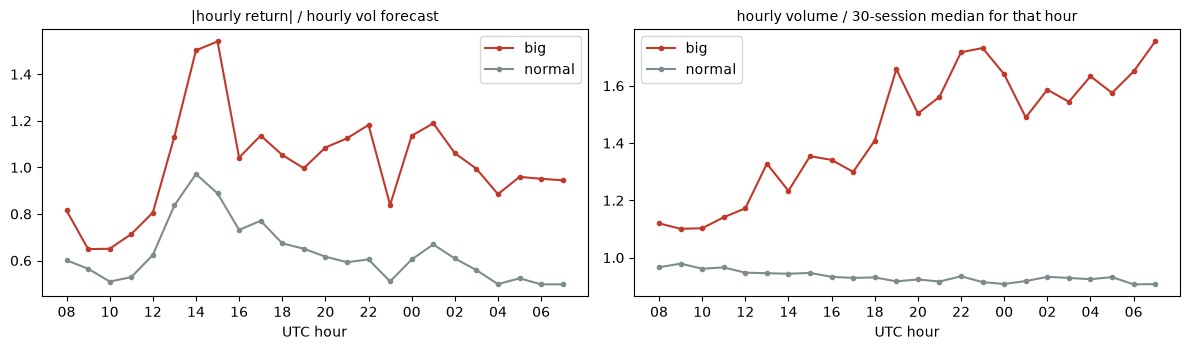

In [4]:
prof = []
for a, r in RES.items():
    prof.append(bm.hourly_profile(r['H'], r['V'], r['table']).assign(asset=a))
prof = pd.concat(prof).groupby(['set', 'hour_after_0800', 'utc_hour'], as_index=False)[['abs_ret_rel', 'volume_rel']].mean()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for s, col in (('big', '#c0392b'), ('normal', '#7f8c8d')):
    g = prof[prof.set == s]
    ax[0].plot(g.hour_after_0800, g.abs_ret_rel, '-o', ms=3, color=col, label=s)
    ax[1].plot(g.hour_after_0800, g.volume_rel, '-o', ms=3, color=col, label=s)
for k, ttl in enumerate(('|hourly return| / hourly vol forecast', 'hourly volume / 30-session median for that hour')):
    ax[k].set_xticks(range(0, 24, 2), [f'{(8 + h) % 24:02d}' for h in range(0, 24, 2)]); ax[k].set_xlabel('UTC hour')
    ax[k].set_title(ttl, fontsize=10); ax[k].legend()
plt.tight_layout(); plt.show()

## 3. What comes before big days (PRE at 08:00, EARLY 08:00–10:00) — screened on dev, confirmed on test

In [5]:
pre = bm.screen(T, bm.PRE, P).assign(group='PRE')
early = bm.screen(T, bm.EARLY, P, target='big_rest').assign(group='EARLY')
SCR = pd.concat([pre, early], ignore_index=True)
cols = ['group', 'feature', 'median_big_dev', 'median_normal_dev', 'auc_dev', 'lo_dev', 'hi_dev', 'candidate',
        'auc_test', 'lo_test', 'hi_test', 'test_level', 'confirmed']
display(SCR[cols].round(3))
print('CONFIRMED:', SCR.loc[SCR.confirmed, ['group', 'feature', 'auc_dev', 'auc_test']].round(3).to_dict(orient='records'))

,group,feature,median_big_dev,median_normal_dev,auc_dev,lo_dev,hi_dev,candidate,auc_test,lo_test,hi_test,test_level,confirmed
0,PRE,pre_rv_prev_vs_fcst,1.019,0.931,0.557,0.502,0.608,True,0.652,0.533,0.756,0.988,True
1,PRE,pre_rv7_vs_rv30,0.898,0.950,0.441,0.391,0.496,True,0.451,0.337,0.564,0.988,False
2,PRE,pre_vol_prev_rel,1.008,0.990,0.517,0.462,0.575,False,0.570,0.454,0.683,0.988,False
3,PRE,pre_trades_prev_rel,1.009,0.996,0.499,0.442,0.553,False,0.548,0.436,0.672,0.988,False
4,PRE,pre_ret_prev_z,0.049,0.021,0.512,0.462,0.563,False,0.479,0.363,0.602,0.988,False
5,PRE,pre_absret_prev_z,0.523,0.518,0.529,0.481,0.580,False,0.547,0.448,0.651,0.988,False
6,PRE,pre_er_prev,0.049,0.049,0.520,0.473,0.568,False,0.519,0.414,0.629,0.988,False
7,PRE,pre_flow_prev,-0.015,-0.014,0.509,0.465,0.554,False,0.484,0.388,0.583,0.988,False
8,PRE,pre_shocks_prev,4.000,3.000,0.547,0.495,0.597,False,0.635,0.526,0.743,0.988,False
9,PRE,pre_last4h_rv_rel,1.002,0.983,0.526,0.473,0.578,False,0.583,0.466,0.693,0.988,False


CONFIRMED: [{'group': 'PRE', 'feature': 'pre_rv_prev_vs_fcst', 'auc_dev': 0.557, 'auc_test': 0.652}]


In [6]:
pa = []
for a in RES:
    d = T[(T.asset == a) & (T.window == 'test') & T.big.notna()]
    for c in bm.PRE + bm.EARLY:
        tg = 'big_rest' if c in bm.EARLY else 'big'
        dd = d[d[tg].notna()]
        pa.append({'asset': a, 'feature': c, 'auc_test': bm.auc(dd[c].to_numpy(float), dd[tg].to_numpy(bool))})
pa = pd.DataFrame(pa).pivot(index='feature', columns='asset', values='auc_test')
print('Per-asset AUC, test window (descriptive):'); display(pa.loc[bm.PRE + bm.EARLY].round(3))

Per-asset AUC, test window (descriptive):


asset,BTC,ETH,SOL,XRP
feature,,,,
pre_rv_prev_vs_fcst,0.631,0.613,0.683,0.684
pre_rv7_vs_rv30,0.431,0.450,0.503,0.422
pre_vol_prev_rel,0.520,0.569,0.598,0.595
pre_trades_prev_rel,0.496,0.531,0.574,0.580
pre_ret_prev_z,0.445,0.458,0.487,0.524
pre_absret_prev_z,0.502,0.536,0.547,0.606
pre_er_prev,0.467,0.509,0.511,0.581
pre_flow_prev,0.519,0.483,0.510,0.435
pre_shocks_prev,0.610,0.644,0.661,0.632


## 4. Do big days cluster? (a regime question)

In [7]:
CL = bm.clustering(T, P)
display(CL.round(4))
dir_ = T[T.big == 1].groupby('window')['up'].mean()
print('Share of big days that are up-moves:', dir_.round(3).to_dict())

,window,stat,value,lo,hi,n
0,dev,P(big next | big) / P(big),1.3735,1.0183,1.7372,2152
1,dev,share of sessions with all 4 assets big (indep...,0.0594,NaN,NaN,539
2,dev,share of big days that are big in >= 3 assets,0.5432,NaN,NaN,539
3,test,P(big next | big) / P(big),1.4834,0.7817,2.2035,772
4,test,share of sessions with all 4 assets big (indep...,0.0567,NaN,NaN,194
5,test,share of big days that are big in >= 3 assets,0.6355,NaN,NaN,194


Share of big days that are up-moves: {'dev': 0.506, 'test': 0.477}


## 5. Save compact outputs

In [8]:
cov.to_csv(OUT / '03_coverage.csv')
desc.to_csv(OUT / '03_during.csv', index=False)
top.to_csv(OUT / '03_top_hour.csv', index=False)
prof.to_csv(OUT / '03_hourly_profile.csv', index=False)
SCR.to_csv(OUT / '03_screen.csv', index=False)
pa.to_csv(OUT / '03_pre_early_by_asset_test.csv')
CL.to_csv(OUT / '03_clustering.csv', index=False)
manifest = {'registration': bm.registration(P), 'synthetic': SYNTHETIC, 'assets': list(RES),
            'thresholds': {a: r['threshold'] for a, r in RES.items()},
            'confirmed': SCR.loc[SCR.confirmed, 'feature'].tolist(), 'run_utc': str(pd.Timestamp.now(tz='UTC'))}
(OUT / '03_manifest.json').write_text(json.dumps(manifest, indent=2, default=str), encoding='utf-8')
print('saved to', OUT, sorted(p.name for p in OUT.iterdir()))

saved to D:\Projects\deribit_market_data\notebooks\Regime_Structure\03 ['03_clustering.csv', '03_coverage.csv', '03_during.csv', '03_hourly_profile.csv', '03_manifest.json', '03_pre_early_by_asset_test.csv', '03_screen.csv', '03_top_hour.csv']
